# Case Study 3: Titanic Survival Prediction using Logistic Regression
**Roll No:** 160124733365 | **Subject:** Fundamentals of Data Science (FDS)

**Problem statement:** Predict whether a passenger survived the Titanic disaster (Survived = 1) from passenger details such as class, sex, age, family size, fare and port of embarkation, and find which factors most affected survival.

*Note: AI assistance (Claude) was used to help write this code; the outputs were run and checked by me.*

## 1. Data Exploration
Importing libraries and loading the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
import pickle

sns.set_style('whitegrid')
df = pd.read_csv('titanic.csv')
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


The dataset has 891 passengers and 12 columns. `Survived` is the target variable.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


`Age`, `Cabin` and `Embarked` have missing values. `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked` are text (object) columns; the rest are numeric.

In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Average age is about 29.7 years. Fare is very skewed (median about 14.5 but max 512). Only about 38% of passengers survived (mean of `Survived`).

In [4]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Cabin is missing for 687 of 891 rows (77%) so it will be dropped. Age (177 missing) and Embarked (2 missing) will be imputed.

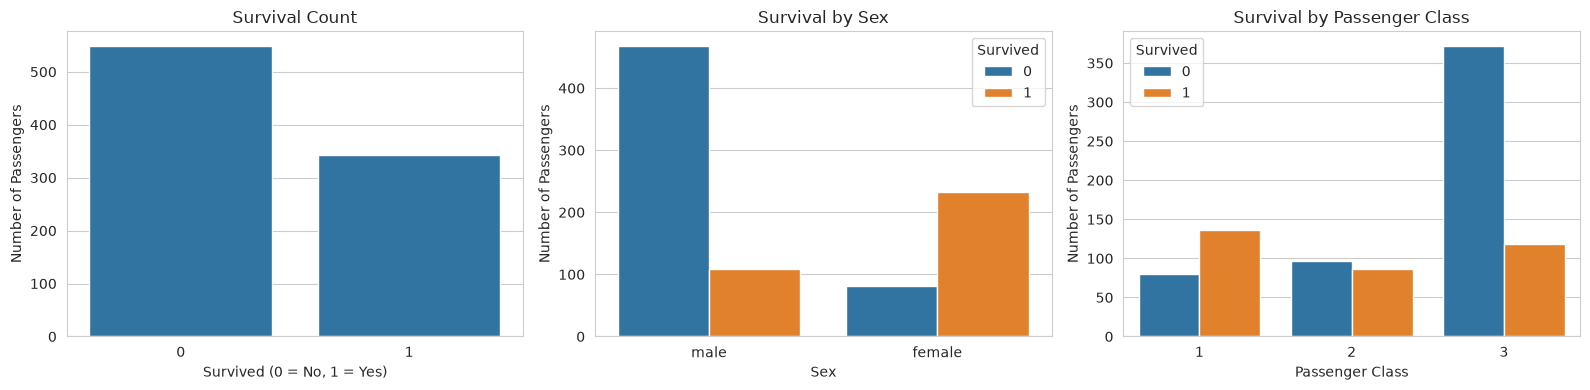

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='Survived', data=df, ax=ax[0])
ax[0].set_title('Survival Count'); ax[0].set_xlabel('Survived (0 = No, 1 = Yes)'); ax[0].set_ylabel('Number of Passengers')
sns.countplot(x='Sex', hue='Survived', data=df, ax=ax[1])
ax[1].set_title('Survival by Sex'); ax[1].set_xlabel('Sex'); ax[1].set_ylabel('Number of Passengers')
sns.countplot(x='Pclass', hue='Survived', data=df, ax=ax[2])
ax[2].set_title('Survival by Passenger Class'); ax[2].set_xlabel('Passenger Class'); ax[2].set_ylabel('Number of Passengers')
plt.tight_layout(); plt.show()
print(df.groupby('Sex')['Survived'].mean())
print(df.groupby('Pclass')['Survived'].mean())

**Interpretation:** 549 passengers died and 342 survived, so the classes are a bit imbalanced. About 74% of females survived but only about 19% of males, so sex is a very strong factor. Survival also drops with class: about 63% in 1st class, 47% in 2nd and 24% in 3rd.

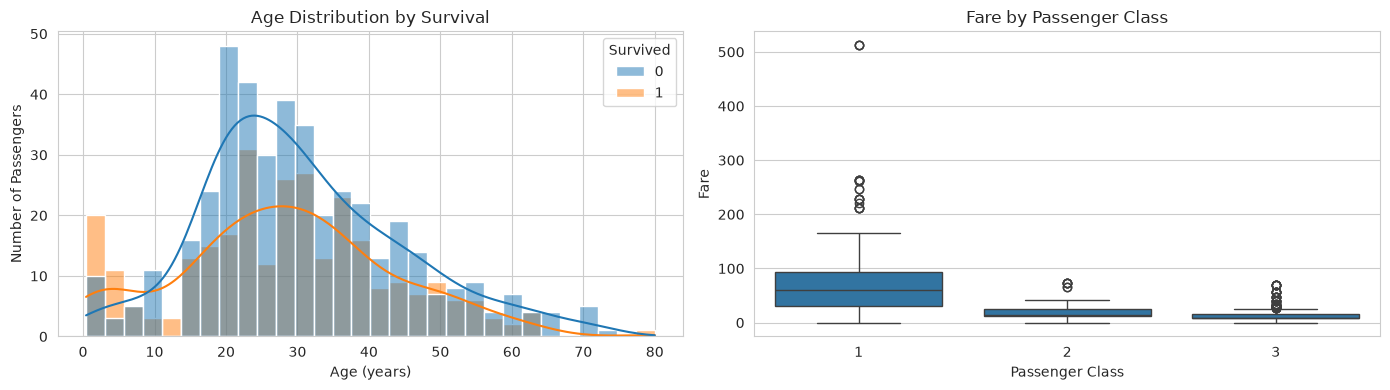

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, ax=ax[0])
ax[0].set_title('Age Distribution by Survival'); ax[0].set_xlabel('Age (years)'); ax[0].set_ylabel('Number of Passengers')
sns.boxplot(x='Pclass', y='Fare', data=df, ax=ax[1])
ax[1].set_title('Fare by Passenger Class'); ax[1].set_xlabel('Passenger Class'); ax[1].set_ylabel('Fare')
plt.tight_layout(); plt.show()

**Interpretation:** Most passengers were 20 to 40 years old. Young children (below about 10) had a better survival rate, which fits the "women and children first" rule. The box plot shows 1st class fares were much higher and had many outliers (up to 512), so fare and class are closely linked.

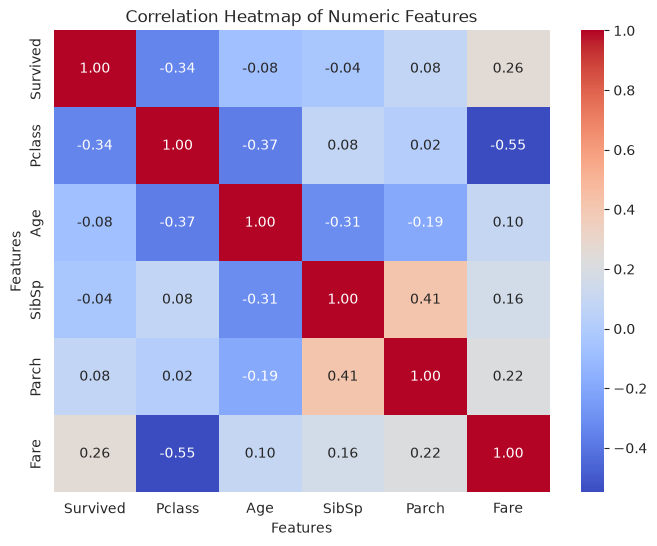

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Survived','Pclass','Age','SibSp','Parch','Fare']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features')
plt.xlabel('Features'); plt.ylabel('Features')
plt.show()

**Interpretation:** Pclass has a negative correlation with survival (-0.34): higher class number (3rd class) means lower survival. Fare has a positive correlation (+0.26). Pclass and Fare are strongly negatively correlated (-0.55) with each other. Age, SibSp and Parch have weak direct correlation with survival.

## 2. Data Preprocessing

In [8]:
data = df.copy()
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
data = pd.get_dummies(data, columns=['Embarked'], drop_first=True, dtype=int)
print(data.isnull().sum().sum())
data.head()

0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


- Age is filled with the median (28) because age is skewed and median is not affected by outliers.
- Embarked is filled with the mode ('S').
- PassengerId, Name, Ticket are identifiers and Cabin is mostly empty, so they are dropped.
- Sex is encoded as 0/1, and Embarked is one-hot encoded (Embarked_Q, Embarked_S; C is the base).
- After this there are no missing values left.

## 3. Model Building
Splitting into 80% train / 20% test (stratified so both sets have the same survival ratio) and scaling features so the coefficients can be compared.

In [9]:
X = data.drop('Survived', axis=1)
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)
print('Train size:', X_train.shape, ' Test size:', X_test.shape)
print('Training accuracy:', round(model.score(X_train_s, y_train), 4))

Train size: (712, 8)  Test size: (179, 8)
Training accuracy: 0.8076


The model is trained on 712 passengers and tested on 179 unseen passengers.

## 4. Model Evaluation

In [10]:
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]
metrics = {'Accuracy': accuracy_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
           'Recall': recall_score(y_test, y_pred), 'F1-score': f1_score(y_test, y_pred),
           'ROC-AUC': roc_auc_score(y_test, y_prob)}
for k, v in metrics.items():
    print(f'{k:10s}: {v:.4f}')
print()
print(classification_report(y_test, y_pred))

Accuracy  : 0.8045
Precision : 0.7931
Recall    : 0.6667
F1-score  : 0.7244
ROC-AUC   : 0.8433

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



**Interpretation of metrics:**
- **Accuracy = 80.4%**: the model correctly predicts 144 out of 179 test passengers. Training accuracy (80.8%) is almost the same, so the model is not overfitting.
- **Precision = 0.79**: when the model says a passenger survived, it is right 79% of the time.
- **Recall = 0.67**: the model finds 67% of the actual survivors; it misses about one third of them.
- **F1-score = 0.72**: balance of precision and recall for the survived class.
- **ROC-AUC = 0.84**: there is an 84% chance the model gives a higher survival probability to a random survivor than to a random non-survivor, which is good separation.

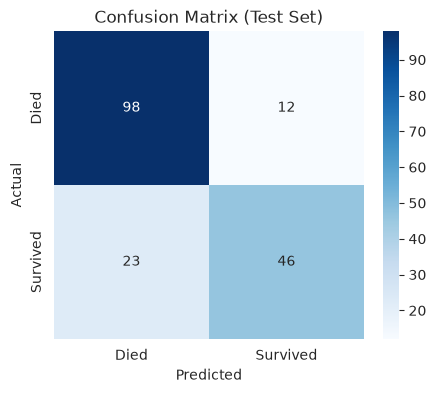

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'])
plt.title('Confusion Matrix (Test Set)'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

**Interpretation:** 98 deaths and 46 survivals were predicted correctly. 12 passengers were wrongly predicted as survived (false positives) and 23 survivors were predicted as died (false negatives). The model is better at identifying deaths than survivals, which is why recall for survivors is lower.

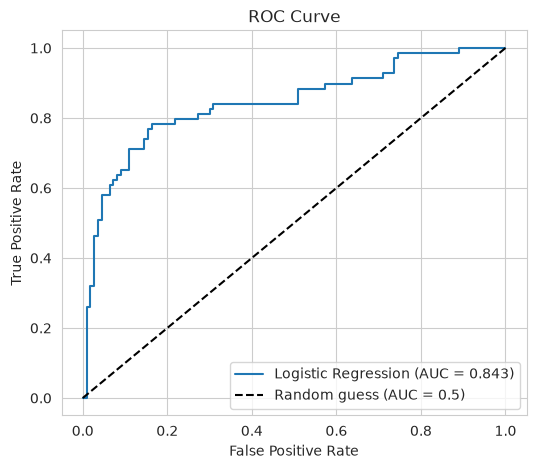

In [12]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {metrics["ROC-AUC"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.title('ROC Curve'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.show()

**Interpretation:** The ROC curve stays well above the diagonal line (random guessing) for all thresholds. AUC = 0.84 means the model separates survivors and non-survivors well. If catching more survivors is important, the threshold can be lowered below 0.5 to raise recall at the cost of some precision.

## 5. Interpretation of Coefficients

   Feature  Coefficient  Odds Ratio
       Sex     1.269598    3.559422
      Fare     0.099599    1.104728
Embarked_Q     0.080683    1.084027
     Parch    -0.067158    0.935048
Embarked_S    -0.171784    0.842161
     SibSp    -0.262672    0.768994
       Age    -0.502878    0.604788
    Pclass    -0.928698    0.395068


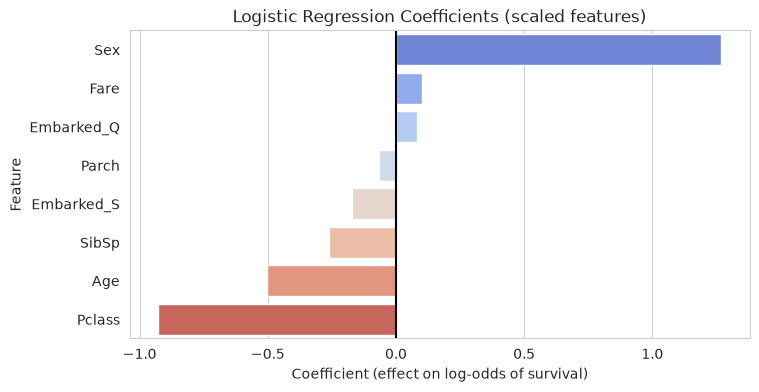

In [13]:
coef = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]})
coef['Odds Ratio'] = np.exp(coef['Coefficient'])
coef = coef.sort_values('Coefficient', ascending=False)
print(coef.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(x='Coefficient', y='Feature', data=coef, hue='Feature', palette='coolwarm', legend=False)
plt.title('Logistic Regression Coefficients (scaled features)')
plt.xlabel('Coefficient (effect on log-odds of survival)'); plt.ylabel('Feature')
plt.axvline(0, color='black'); plt.show()

**Interpretation (features are standardised, so coefficients can be compared):**
- **Sex (+1.27, odds ratio 3.56):** the strongest factor. Being female increases the odds of survival about 3.6 times per standard deviation, matching the 74% vs 19% survival seen in EDA.
- **Pclass (-0.93, OR 0.40):** second most important. Moving towards 3rd class strongly lowers the odds of survival.
- **Age (-0.50, OR 0.60):** older passengers had lower odds of survival; children were given priority.
- **SibSp (-0.26):** passengers with many siblings/spouses aboard survived less, probably because large families found it harder to escape together.
- **Embarked_S (-0.17):** boarding at Southampton slightly lowers the odds compared to Cherbourg.
- **Fare (+0.10), Embarked_Q (+0.08), Parch (-0.07):** very small effects. Fare is weak here because most of its information is already captured by Pclass.

## 6. Saving the Model for Streamlit Deployment
The trained model and scaler are saved with pickle so that `app.py` (Streamlit app) can load them and predict for user inputs. Run with `streamlit run app.py`.

In [14]:
with open('model.pkl', 'wb') as f:
    pickle.dump({'model': model, 'scaler': scaler, 'columns': list(X.columns)}, f)
print('Saved model.pkl')

Saved model.pkl


## 7. Conclusion
- Logistic regression predicted Titanic survival with **80.4% accuracy** and **ROC-AUC of 0.84** on unseen test data, with no sign of overfitting.
- **Sex, passenger class and age** are the most significant predictors. Females, 1st-class passengers and children had the highest chance of survival.
- Recall for survivors (0.67) is lower than precision (0.79), so the model misses some survivors; adjusting the threshold or adding features such as title from Name or family size could improve it.
- The trained model is saved and deployed through a Streamlit app (`app.py`) where a user can enter passenger details and get a survival probability.